M2 CL Lab1 Code

CHEN Peng 22409126




In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**2 Getting the Data**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
#2.2
path = "/content/drive/MyDrive/M2-pariscite/phoible.csv"
# or for easily reprodutible,
# path = "https://raw.githubusercontent.com/phoible/dev/v2.0/data/phoible.csv"
df = pd.read_csv(path)
df = pd.read_csv(path)
print(df.head(1))
print("Number of rows:", len(df))
print("Number of inventories:", df["InventoryID"].nunique())
print("Number of Glottocodes:", df["Glottocode"].nunique())

   InventoryID Glottocode ISO6393 LanguageName SpecificDialect GlyphID  \
0            1   kore1280     kor       Korean             NaN    0061   

  Phoneme Allophones Marginal SegmentClass  ... retractedTongueRoot  \
0       a          a      NaN        vowel  ...                   -   

  advancedTongueRoot periodicGlottalSource epilaryngealSource spreadGlottis  \
0                  -                     +                  -             -   

  constrictedGlottis fortis raisedLarynxEjective loweredLarynxImplosive click  
0                  -      0                    -                      -     0  

[1 rows x 48 columns]
Number of rows: 105467
Number of inventories: 3020
Number of Glottocodes: 2184


/tmp/ipykernel_174/2074586423.py:3: DtypeWarning: Columns (4,7,8,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


In [ ]:
# 2.4
latest_inventory = df.groupby("Glottocode")["InventoryID"].max().reset_index()
df_selected = df.merge(latest_inventory,on=["Glottocode", "InventoryID"])

In [ ]:
#2.5
multi_inventory_languages = (df.groupby("Glottocode")["InventoryID"].nunique())
multi_inventory_languages = multi_inventory_languages[ multi_inventory_languages > 3]
sample_languages = multi_inventory_languages.sample(5, random_state=42).index

for glottocode in sample_languages:
    language_data = df[df["Glottocode"] == glottocode]

    inventories = [
        set(group["Phoneme"])
        for _, group in language_data.groupby("InventoryID")
    ]

    sizes = [len(x) for x in inventories]
    print(
        language_data["LanguageName"].iloc[0],
        "| sizes:", sizes,
        "| same phonemes:", all(x == inventories[0] for x in inventories)
    )

French | sizes: [40, 37, 36, 34] | same phonemes: False
Udmurt | sizes: [36, 36, 37, 33] | same phonemes: False
fulfulde | sizes: [34, 36, 47, 39] | same phonemes: False
Igbo | sizes: [65, 59, 36, 35] | same phonemes: False
Bidyara | sizes: [20, 17, 18, 21, 19] | same phonemes: False


In [ ]:
# 2.6
inventory_sizes = (
    df.groupby(["Source", "InventoryID"]).size()
      .reset_index(name="InventorySize")
)

#print(inventory_sizes.head(2))

# compare the inventory size from the different sources
source_stats = (inventory_sizes.groupby("Source")["InventorySize"].describe())
print(source_stats)

        count       mean        std   min   25%   50%    75%    max
Source                                                             
aa      203.0  39.724138   8.771734  22.0  34.0  38.0  44.00   82.0
ea      390.0  43.292308  14.319767  19.0  34.0  40.0  49.75  133.0
er      392.0  24.038265   4.836568  16.0  21.0  23.0  26.00   44.0
gm      460.0  41.917391  14.541718  18.0  33.0  39.0  47.00  161.0
ph      389.0  34.089974  11.452035  14.0  25.0  33.0  41.00   90.0
ra      100.0  42.610000   8.491106  21.0  36.0  42.0  48.00   62.0
saphon  355.0  25.495775   6.184714  11.0  21.0  25.0  29.00   51.0
spa     197.0  38.406091  12.957055  17.0  28.0  37.0  45.00   94.0
upsid   451.0  30.966741  11.554364  11.0  23.5  29.0  36.00  141.0
uz       83.0  44.686747  14.378955  21.0  34.5  41.0  55.50   74.0


Average number of vowels: 10.192765567765568


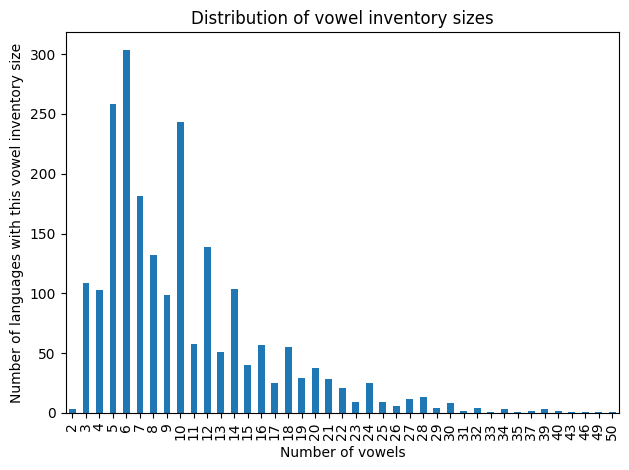

In [ ]:
#2.8
# keep only vowels
vowels = df_selected[df_selected["SegmentClass"] == "vowel"]
# vowel inventory size for each language
vowel_counts = vowels.groupby("Glottocode").size()
print("Average number of vowels:", vowel_counts.mean())
distribution = vowel_counts.value_counts().sort_index()

distribution.plot(kind="bar")
plt.xlabel("Number of vowels")
plt.ylabel("Number of languages with this vowel inventory size")
plt.title("Distribution of vowel inventory sizes")
plt.tight_layout()
plt.show()

Q1: 6.0
Q3: 13.0
IQR: 7.0
Lower bound: -4.5
Upper bound: 23.5
Number of outliers: 99


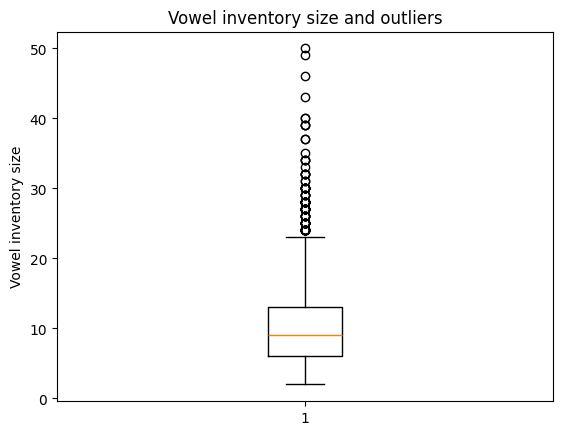

In [ ]:
#10
Q1, Q3 = vowel_counts.quantile([0.25, 0.75])
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = vowel_counts[(vowel_counts < lower) | (vowel_counts > upper)]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower)
print("Upper bound:", upper)
print("Number of outliers:", len(outliers))

plt.boxplot(vowel_counts)
plt.ylabel("Vowel inventory size")
plt.title("Vowel inventory size and outliers")
plt.show()

In [ ]:
#11
top_vowels = (vowels.groupby("Phoneme")["Glottocode"].nunique().sort_values(ascending=False).head(3))
print(top_vowels)

Phoneme
i    2059
u    1966
a    1922
Name: Glottocode, dtype: int64


In [ ]:
#12
total_languages = df_selected["Glottocode"].nunique()

for vowel in ["i", "a", "u"]:
    count = vowels[vowels["Phoneme"] == vowel]["Glottocode"].nunique()
    proportion = count / total_languages
    print(vowel, proportion)

phoneme_sets = vowels.groupby("Glottocode")["Phoneme"].apply(set)
all_three = phoneme_sets.apply(lambda x: {"i", "a", "u"}.issubset(x))
print("i+a+u:", all_three.sum() / total_languages)

i 0.9427655677655677
a 0.88003663003663
u 0.9001831501831502
i+a+u: 0.7976190476190477


In [ ]:
#13
import unicodedata
#Convert the ‘vowel with a diacritical mark’ back to its basic vowel letter
def clean_vowel(x):
    x = unicodedata.normalize("NFD", x)
    x = "".join(c for c in x if unicodedata.category(c) != "Mn")
    return x.replace("ː", "").replace("ˑ", "")

vowels = vowels.copy()
vowels["base"] = vowels["Phoneme"].apply(clean_vowel)

for v in ["i", "a", "u"]:
    count = vowels[vowels["base"] == v]["Glottocode"].nunique()
    print(v, count / total_languages)

base_sets = vowels.groupby("Glottocode")["base"].apply(set)
all_three_close = base_sets.apply(lambda x: {"i", "a", "u"}.issubset(x))
print("i+a+u (close equivalents):",
      all_three_close.sum() / total_languages)

i 0.9716117216117216
a 0.9317765567765568
u 0.9290293040293041
i+a+u (close equivalents): 0.8644688644688645


In [ ]:
#14
language_vowels = (vowels.groupby("Glottocode")["base"].apply(set)) # the base vowels for each language
violations = language_vowels[~language_vowels.apply(lambda x: {"i", "a", "u"}.issubset(x))]
print("Number of violations:", len(violations), 1 - (len(violations)/len(language_vowels)))

examples = violations.tail(3)
for code, phonemes in examples.items():
    name = df_selected.loc[
        df_selected["Glottocode"] == code,
        "LanguageName"
    ].iloc[0]

    missing = {"i", "a", "u"} - phonemes

    print(name)
    print("Missing:", missing)
    print("Vowels:", phonemes)
    print()

Number of violations: 296 0.8644688644688645
Euchee; Yuchi
Missing: {'a'}
Vowels: {'e', 'u', 'o', 'i', 'ɑ', 'æ'}

zande
Missing: {'i', 'u'}
Vowels: {'ɛ', 'a', 'ʊ', 'ɪ', 'ɔ'}

zulgo
Missing: {'i', 'u'}
Vowels: {'ə', 'a'}



In [ ]:
#15
languages_selected = ["Euchee; Yuchi", "zande", "zulgo"]
check = df[(df["LanguageName"].isin(languages_selected)) &
          (df["SegmentClass"] == "vowel")][["LanguageName", "InventoryID", "Phoneme", "Marginal", "Source"]]
print(check.to_string(index=False))

 LanguageName  InventoryID Phoneme Marginal Source
        zande          849       a    False     aa
        zande          849       ɛ    False     aa
        zande          849       ɪ    False     aa
        zande          849       ɔ    False     aa
        zande          849       ʊ    False     aa
        zulgo          851       a    False     aa
        zulgo          851       ə    False     aa
Euchee; Yuchi         1074       æ    False     ph
Euchee; Yuchi         1074      æ̃    False     ph
Euchee; Yuchi         1074       ɑ    False     ph
Euchee; Yuchi         1074      ɑ̃    False     ph
Euchee; Yuchi         1074       e    False     ph
Euchee; Yuchi         1074      ẽ    False     ph
Euchee; Yuchi         1074       i    False     ph
Euchee; Yuchi         1074      ĩ    False     ph
Euchee; Yuchi         1074       o    False     ph
Euchee; Yuchi         1074      õ    False     ph
Euchee; Yuchi         1074       u    False     ph


In [ ]:
# 16
# nasal vowels
nasal_languages = vowels[vowels["nasal"] == "+"]["Glottocode"].unique()

# long vowels
long_languages = vowels[vowels["long"] == "+"]["Glottocode"].unique()

# front rounded vowels
front_rounded_languages = vowels[
    (vowels["front"] == "+") & (vowels["round"] == "+")]["Glottocode"].unique()

print("Nasal:", len(nasal_languages))
print("Long:", len(long_languages))
print("Front rounded:", len(front_rounded_languages))


Nasal: 473
Long: 821
Front rounded: 173


In [ ]:
# 17

# all phonological feature columns
feature_cols = vowels.loc[:, "tone":"click"].columns.tolist()


# nasal -> oral
nasal_results = []
for code in nasal_languages:
    data = vowels[vowels["Glottocode"] == code]
    nasal_vowels = data[data["nasal"] == "+"]
    oral_vowels = data[data["nasal"] == "-"]
    other_features = [f for f in feature_cols if f != "nasal"]

    result = all(
        any((oral_vowels[other_features] == row[other_features]).all(axis=1))
        for _, row in nasal_vowels.iterrows()
    )
    nasal_results.append(result)

print("Nasal:",sum(nasal_results) / len(nasal_results),
      "exceptions:", nasal_results.count(False))


# 2. long -> non-long
long_results = []
for code in long_languages:
    data = vowels[vowels["Glottocode"] == code]
    long_vowels = data[data["long"] == "+"]
    short_vowels = data[data["long"] == "-"]
    other_features = [f for f in feature_cols if f != "long"]

    result = all(
        any((short_vowels[other_features] == row[other_features]).all(axis=1))
        for _, row in long_vowels.iterrows()
    )
    long_results.append(result)

print("Long:",sum(long_results) / len(long_results),
      "exceptions:", long_results.count(False))


# y -> i and u
y_languages = vowels[vowels["Phoneme"] == "y"]["Glottocode"].unique()
y_results = []
for code in y_languages:
    inv = set(vowels[vowels["Glottocode"] == code]["Phoneme"])
    y_results.append("i" in inv and "u" in inv)

print("y:",sum(y_results) / len(y_results),
      "exceptions:", y_results.count(False))

Nasal: 0.8837209302325582 exceptions: 55
Long: 0.7758830694275274 exceptions: 184
y: 0.8981481481481481 exceptions: 11


In [ ]:
#20
A = "y"
B = "i"
language_phonemes = df_selected.groupby("Glottocode")["Phoneme"].apply(set)
has_y = language_phonemes.apply(lambda x: "y" in x)
has_i = language_phonemes.apply(lambda x: "i" in x)
table = pd.crosstab(has_y, has_i)
table.index.name = "y"
table.columns.name = "i"
print(table)


i      False  True 
y                  
False    119   1957
True       6    102


In [ ]:
#21
from scipy.stats import chi2_contingency
chi2, p, dof, expected = chi2_contingency(table)
print("chi2 =", chi2, "; p =", p)

chi2 = 0.0 ; p = 1.0


In [ ]:
#22
from sklearn.metrics import mutual_info_score
mi = mutual_info_score(has_y, has_i)
p1_1 = (has_y & has_i).mean()
expected = has_y.mean() * has_i.mean()
print("MI =", mi)
print("p(1,1) =", p1_1)
print("p(y=1)p(i=1) =", expected)

MI = 1.370768209975337e-06
p(1,1) = 0.046703296703296704
p(y=1)p(i=1) = 0.046620275329066534


In [ ]:
#24
freq = (vowels.groupby("Phoneme")["Glottocode"].nunique().sort_values())
print(freq[(freq > 1) & (freq <= 10)].head(5))
has_ay = language_phonemes.apply(lambda x: "ay" in x)
has_i = language_phonemes.apply(lambda x: "i" in x)
rare_table = pd.crosstab(has_ay, has_i)
rare_table.index.name = "ay"
rare_table.columns.name = "i"

print(rare_table)
print()
chi2, p_chi, dof, expected = chi2_contingency(rare_table)
print(expected)
print("Chi-square p =", p_chi)

from scipy.stats import fisher_exact
oddsratio, p_fisher = fisher_exact(rare_table)
print("Fisher p =", p_fisher)

Phoneme
ʌ̃ː    2
aːu    2
aɪ̃    2
ʊ̯     2
ay     2
Name: Glottocode, dtype: int64
i      False  True 
ay                 
False    125   2057
True       0      2

[[1.24885531e+02 2.05711447e+03]
 [1.14468864e-01 1.88553114e+00]]
Chi-square p = 1.0
Fisher p = 1.0


In [ ]:
# 25

import numpy as np
from scipy.stats import chi2, false_discovery_control
# language × phoneme
presence = pd.crosstab(df_selected["Glottocode"],df_selected["Phoneme"]) > 0

X = presence.to_numpy(dtype=np.int32)
n_languages = X.shape[0]
n_phonemes = X.shape[1]

# number of all phoneme pairs
n_tests = n_phonemes * (n_phonemes - 1) // 2
expected_false_positives = n_tests * 0.05

print("Number of phonemes:", n_phonemes)
print("Number of tests:", n_tests)
print("Expected false positives:", expected_false_positives)


# number of languages containing each phoneme
freq = X.sum(axis=0)
# number of languages containing both phonemes
both = X.T @ X
# only keep each pair once: upper triangle
i, j = np.triu_indices(n_phonemes, k=1)

n11 = both[i, j]          # A present, B present
n10 = freq[i] - n11       # A present, B absent
n01 = freq[j] - n11       # A absent, B present
n00 = n_languages - n11 - n10 - n01


# Pearson chi-square for every 2x2 table
numerator = n_languages * (n11 * n00 - n10 * n01) ** 2
denominator = (
    (n11 + n10) *
    (n01 + n00) *
    (n11 + n01) *
    (n10 + n00)
)

chi2_values = numerator / denominator
p_values = chi2.sf(chi2_values, df=1)

# significant before correction
print("Significant before correction:",np.sum(p_values < 0.05))

# Benjamini-Hochberg correction
p_corrected = false_discovery_control(p_values,method="bh")
print("Significant after BH:",np.sum(p_corrected < 0.05))

Number of phonemes: 2609
Number of tests: 3402136
Expected false positives: 170106.80000000002
Significant before correction: 121374
Significant after BH: 89708


In [ ]:
# 26
names = np.array(presence.columns)
phi = (n11 * n00 - n10 * n01) / np.sqrt(
    (n11 + n10) * (n01 + n00) * (n11 + n01) * (n10 + n00))

result = pd.DataFrame({
    "phoneme1": names[i],
    "phoneme2": names[j],
    "p": p_values,
    "phi": abs(phi)
})

print("Top 10 by p-value:")
print(result.sort_values("p").head(10))
print()
print("Top 10 by effect size:")
print(result.sort_values("phi", ascending=False).head(10))

Top 10 by p-value:
        phoneme1 phoneme2    p  phi
1069112    i̯ũo      ũo  0.0  1.0
2989472     ɔy̯ː      ɔ̞ː  0.0  1.0
643251     d̺ʒ̺ʷ      z̪̻  0.0  1.0
1303906      kʲː      βʲː  0.0  1.0
1877222   õ̞ãˤ      tsˠ  0.0  1.0
1473382      mbˠ       ŋh  0.0  1.0
1223672      kǂh       oᴱ  0.0  1.0
2659583      xʲː      ʰkʲ  0.0  1.0
2659601      xʲː      ʰtʲ  0.0  1.0
2659598      xʲː      ʰtɕ  0.0  1.0

Top 10 by effect size:
        phoneme1 phoneme2    p  phi
736754        ĕ      ɛa̟  0.0  1.0
3402051   ⁿt͇s͇ʰ     ⁿʈɽʰ  0.0  1.0
3402046   ⁿt͇s͇ʰ      ⁿɖɽ  0.0  1.0
3402038   ⁿt̪s̪ʰ     ⁿʈɽʰ  0.0  1.0
3402033   ⁿt̪s̪ʰ      ⁿɖɽ  0.0  1.0
736760        ĕ       ɛɐ  0.0  1.0
1223308      kǂh    kǂkxʼ  0.0  1.0
3402074      ⁿɖɽ     ⁿʈɽʰ  0.0  1.0
563346       d̪x       ɢʱ  0.0  1.0
1697485     n̤ɡ̤      psʰ  0.0  1.0


In [ ]:
# 27 - shuffle inventories while keeping:
# 1. each language's inventory size unchanged
# 2. each phoneme's overall frequency unchanged

def shuffle(X: np.ndarray, seed: int = 42) -> np.ndarray:
    """
    X:  Binary language × phoneme matrix.
        Rows = languages, columns = phonemes.
        1 = phoneme present, 0 = absent.
    return: Shuffled binary matrix with the same shape as X.
    """
    rng = np.random.default_rng(seed)
    # phonemes present in each language
    rows = [set(np.flatnonzero(row)) for row in X]

    # randomly exchange phonemes between two languages
    for _ in range(20000):
        r1, r2 = rng.choice(len(rows), 2, replace=False)
        only1 = list(rows[r1] - rows[r2])
        only2 = list(rows[r2] - rows[r1])
        if only1 and only2:
            x = rng.choice(only1)
            y = rng.choice(only2)
            rows[r1].remove(x)
            rows[r1].add(y)
            rows[r2].remove(y)
            rows[r2].add(x)
    # convert back to a binary matrix
    Y = np.zeros_like(X)

    for r, sounds in enumerate(rows):
        Y[r, list(sounds)] = 1
    return Y

In [ ]:
# 27
keep = p_corrected < 0.05
a, b = i[keep], j[keep]
real_effect = abs(phi[keep])

# shuffled null model
Y = shuffle(X, seed=42)

freq = Y.sum(axis=0)
both = Y.T @ Y

n11_null = both[a, b]
n10_null = freq[a] - n11_null
n01_null = freq[b] - n11_null
n00_null = len(Y) - n11_null - n10_null - n01_null

null_effect = abs(
    (n11_null * n00_null - n10_null * n01_null) /
    np.sqrt((n11_null + n10_null) * (n01_null + n00_null) * (n11_null + n01_null) * (n10_null + n00_null)))

# real association is larger than the shuffled baseline
remain = real_effect > null_effect
print("Associations before null model:", len(a))
print("Associations remaining after comparison with null model:", remain.sum())

Associations before null model: 89708
Associations remaining after comparison with null model: 52752


In [ ]:
# 29
# language metadata
url = "https://raw.githubusercontent.com/cldf-datasets/phoible/master/cldf/languages.csv"
meta = pd.read_csv(url)

# one row per language in our sample
languages = df_selected[["Glottocode", "LanguageName"]].drop_duplicates("Glottocode")

# add family and macroarea
languages = languages.merge(
    meta[["Glottocode", "Family_Name", "Macroarea"]],
    on="Glottocode",how="left"
)

# family distribution
family_table = (
    languages["Family_Name"].value_counts(dropna=False).reset_index())
family_table.columns = ["Family", "Languages"]

# macroarea distribution
area_table = (
    languages["Macroarea"].value_counts(dropna=False).reset_index())
area_table.columns = ["Macroarea", "Languages"]

print("Most represented families:")
print(family_table.head(10))

print("\nMacroareas:")
print(area_table)

Most represented families:
           Family  Languages
0  Atlantic-Congo        420
1    Pama-Nyungan        253
2   Indo-European        146
3    Austronesian        110
4    Afro-Asiatic        107
5    Sino-Tibetan         99
6             NaN         93
7          Tupian         50
8        Arawakan         43
9           Mande         43

Macroareas:
       Macroarea  Languages
0         Africa        714
1        Eurasia        448
2      Australia        343
3  South America        332
4      Papunesia        183
5  North America        141
6            NaN         23


In [ ]:
# 30
# one language per family
info = languages.copy()
info["family"] = info["Family_Name"].fillna(info["Glottocode"])
balanced = (info.groupby("family", group_keys=False)
        .sample(1, random_state=42))

codes = balanced["Glottocode"]
sample_vowels = vowels[vowels["Glottocode"].isin(codes)].copy()
print("Languages in balanced sample:", len(codes))

Languages in balanced sample: 269


In [ ]:
# 30
# for the 1st universal)
for sound in ["i", "a", "u"]:
    count = sample_vowels[sample_vowels["base"] == sound]["Glottocode"].nunique()
    print(sound, count / len(codes))
sets = sample_vowels.groupby("Glottocode")["base"].apply(set)
print("i+a+u:",sets.apply(lambda x: {"i", "a", "u"}.issubset(x)).mean())

i 0.966542750929368
a 0.9405204460966543
u 0.9033457249070632
i+a+u: 0.8438661710037175


In [ ]:
# for the 2nd universal
features = sample_vowels.loc[:, "tone":"click"].columns.tolist()
#Compute the proportion of languages satisfying a marked-vowel implication
def implication(feature: str) -> float:
    # feature: phonological feature to test, e.g. "nasal" or "long"
    # return: proportion of languages satisfying the implication
    langs = sample_vowels[sample_vowels[feature] == "+"]["Glottocode"].unique()
    result = []
    other = [f for f in features if f != feature]

    for code in langs:
        data = sample_vowels[sample_vowels["Glottocode"] == code]
        marked = data[data[feature] == "+"]
        simple = data[data[feature] == "-"]
        result.append(
            all(any((simple[other] == row[other]).all(axis=1))for _, row in marked.iterrows()))
    return sum(result) / len(result)

print("Nasal -> oral:", implication("nasal"))
print("Long -> non-long:", implication("long"))

phoneme_sets = (sample_vowels.groupby("Glottocode")["Phoneme"].apply(set))
with_y = phoneme_sets[phoneme_sets.apply(lambda x: "y" in x)]

print("y -> i+u:",with_y.apply(lambda x: "i" in x and "u" in x).mean())

Nasal -> oral: 0.9818181818181818
Long -> non-long: 0.7654320987654321
y -> i+u: 0.8571428571428571


In [ ]:
# Q31 — repeat the balanced sampling 100 times
# Compute the proportion of languages satisfying a marked-vowel implication for one random genealogically balanced sample.
def sample_implication(sample_vowels: pd.DataFrame,feature: str) -> float:
    """
    sample_vowels: Vowel data from the current random sample.
    feature: Feature to test, e.g. "nasal" or "long".
    return: Proportion of languages satisfying the implication.
    """
    # phonological feature columns
    features = sample_vowels.loc[:, "tone":"click"].columns.tolist()
    # all features except the tested one
    other_features = [f for f in features if f != feature]
    # languages containing at least one marked vowel
    langs = sample_vowels[sample_vowels[feature] == "+"]["Glottocode"].unique()
    result = []

    for code in langs:
        # vowels of one language
        language_vowels = sample_vowels[sample_vowels["Glottocode"] == code]

        # marked vowels: e.g. nasal = "+"
        marked = language_vowels[language_vowels[feature] == "+"]

        # possible simpler counterparts: e.g. nasal = "-"
        simple = language_vowels[language_vowels[feature] == "-"]

        # check whether every marked vowel has a simpler counterpart
        ok = all(
            any((simple[other_features] == row[other_features]).all(axis=1))
            for _, row in marked.iterrows())
        result.append(ok)
    return sum(result) / len(result)


results = []

# Repeat the random sampling 100 times
for seed in range(100):
    # One random language per family
    sample = (info.groupby("family", group_keys=False).sample(1, random_state=seed))
    # Glottocodes of selected languages
    codes = sample["Glottocode"]
    # Vowels from the selected languages
    sample_vowels = vowels[vowels["Glottocode"].isin(codes)].copy()

    # ----- First universal -----
    # Basic vowel symbols for each language
    base_sets = (sample_vowels.groupby("Glottocode")["base"].apply(set))

    # Proportion containing i + a + u together
    triangle = base_sets.apply(lambda x: {"i", "a", "u"}.issubset(x)).mean()

    # ----- Second universal -----
    nasal = sample_implication(sample_vowels, "nasal")
    long = sample_implication(sample_vowels, "long")

    # y -> i + u
    # Phoneme set of each language
    phoneme_sets = (sample_vowels.groupby("Glottocode")["Phoneme"].apply(set))
    # Languages containing y
    y_sets = phoneme_sets[phoneme_sets.apply(lambda x: "y" in x)]
    # Among languages with y, proportion also containing i and u
    y_result = y_sets.apply(lambda x: "i" in x and "u" in x).mean()
    # Save the four proportions from this sampling
    results.append([triangle,nasal,long,y_result])

# One row = one random sampling
results = pd.DataFrame(results,columns=["i+a+u", "nasal", "long", "y"])

# Summary of the distributions
print(results.describe())
print(results.quantile([0.025, 0.975])) # 95% interval, less sensitive to extreme random samples than min/max

            i+a+u       nasal        long           y
count  100.000000  100.000000  100.000000  100.000000
mean     0.834907    0.933957    0.762454    0.876893
std      0.011792    0.027992    0.028170    0.097758
min      0.806691    0.859649    0.689189    0.500000
25%      0.825279    0.911889    0.745757    0.833333
50%      0.836431    0.942308    0.765432    0.857143
75%      0.843866    0.946664    0.782191    1.000000
max      0.862454    1.000000    0.850746    1.000000
          i+a+u     nasal      long         y
0.025  0.812175  0.882904  0.700565  0.689286
0.975  0.858736  0.982615  0.809840  1.000000


In [ ]:
results.describe()
results.quantile([0.025, 0.975])

,i+a+u,nasal,long,y
0.025,0.812175,0.882904,0.700565,0.689286
0.975,0.858736,0.982615,0.809840,1.000000


In [ ]:
# 33 - support of size-1 itemsets

# presence: language × phoneme presence/absence matrix， already created in Q25
# rows = languages, columns = phonemes
# True = the language has this phoneme, False = it does not
presence = pd.crosstab(df_selected["Glottocode"], df_selected["Phoneme"]) > 0

# support = proportion of languages containing each phoneme
support_1 = (presence.mean().sort_values(ascending=False).reset_index())
support_1.columns = ["Phoneme", "Support"]
print(support_1.head(5))

  Phoneme   Support
0       m  0.965201
1       i  0.942766
2       k  0.907509
3       u  0.900183
4       j  0.900183


In [ ]:
# 34 - support of all size-2 itemsets
X = presence.to_numpy(dtype=np.int32)
phonemes = np.array(presence.columns)
# Number of languages containing each pair of phonemes
both = X.T @ X
# All possible phoneme pairs, without duplicates
i, j = np.triu_indices(len(phonemes), k=1)
support_2 = pd.DataFrame({
    "Phoneme1": phonemes[i],
    "Phoneme2": phonemes[j],
    "Support": both[i, j] / len(presence)
})
support_2 = support_2.sort_values("Support", ascending=False).reset_index(drop=True)
print(support_2.head(5))

  Phoneme1 Phoneme2   Support
0        i        m  0.909799
1        i        u  0.892399
2        k        m  0.874542
3        j        m  0.873626
4        m        u  0.869048


In [ ]:
# 35 - define frequent itemsets with a 10% minimum support threshold
min_support = 0.10
frequent_1 = support_1[support_1["Support"] > min_support]
frequent_2 = support_2[support_2["Support"] > min_support]
print("Frequent size-1 itemsets:", len(frequent_1))
print("Frequent size-2 itemsets:", len(frequent_2))

Frequent size-1 itemsets: 77
Frequent size-2 itemsets: 1124


In [ ]:
#36 inspect frequent itemsets of size 2
print(frequent_2.sort_values("Support", ascending=False).head(10))

  Phoneme1 Phoneme2   Support
0        i        m  0.909799
1        i        u  0.892399
2        k        m  0.874542
3        j        m  0.873626
4        m        u  0.869048
5        i        k  0.863095
6        i        j  0.847985
7        a        m  0.846154
8        a        i  0.842949
9        k        p  0.838370


In [ ]:
#37 confidence and lift for i -> u
X = "u"
Y = "i"
support_X = support_1.loc[support_1["Phoneme"] == X, "Support"].iloc[0]
support_Y = support_1.loc[support_1["Phoneme"] == Y, "Support"].iloc[0]
support_XY = support_2.loc[
    ((support_2["Phoneme1"] == X) & (support_2["Phoneme2"] == Y)) |
    ((support_2["Phoneme1"] == Y) & (support_2["Phoneme2"] == X)),
    "Support"
].iloc[0]

confidence = support_XY / support_X
lift = confidence / support_Y
print("Confidence:", confidence)
print("Lift:", lift)

Confidence: 0.9913530010172941
Lift: 1.0515371317249977


In [ ]:
# Q37 - compute confidence and lift for an association rule X -> Y

def association_rule(X: str, Y: str) -> dict:
    """
    X, Y: Two phonemes in the association rule X -> Y.
    return: Support of the pair, confidence and lift.
    """
    support_X = support_1.loc[support_1["Phoneme"] == X, "Support"].iloc[0]
    support_Y = support_1.loc[support_1["Phoneme"] == Y, "Support"].iloc[0]


    pair = support_2[
        ((support_2["Phoneme1"] == X) & (support_2["Phoneme2"] == Y)) |
        ((support_2["Phoneme1"] == Y) & (support_2["Phoneme2"] == X))
    ]
    support_XY = pair["Support"].iloc[0]

    # confidence = P(Y | X)
    confidence = support_XY / support_X
    # lift = P(Y | X) / P(Y)
    lift = confidence / support_Y

    return {"Rule": f"{X} -> {Y}","Support": support_XY,
        "Confidence": confidence,"Lift": lift}

In [ ]:
#37
tests = [
    ("i", "m"),
    ("i", "u"),
    ("k", "m"),
    ("j", "m"),
    ("a", "i")
]
tests_results = pd.DataFrame([
    association_rule(X, Y) for X, Y in tests])
print(tests_results)

     Rule   Support  Confidence      Lift
0  i -> m  0.909799    0.965032  0.999824
1  i -> u  0.892399    0.946576  1.051537
2  k -> m  0.874542    0.963673  0.998416
3  j -> m  0.873626    0.970498  1.005488
4  a -> i  0.842949    0.957856  1.016007


In [ ]:
# 39 binary language × phoneme matrix
binary_matrix = presence.astype(int)
print(binary_matrix.head())

Phoneme     N  R  R̪  R̪|R  R̪̥|R̥  R̪̰|R̰  a  ae  ae̞  ae̞ˤ  ...  ⁿɟ  ⁿɡ  ⁿɢ  \
Glottocode                                                    ...               
aari1239    0  0   0     0       0       0  1   0    0     0  ...   0   0   0   
abar1238    0  0   0     0       0       0  1   0    0     0  ...   0   0   0   
abau1245    0  0   0     0       0       0  0   0    0     0  ...   0   0   0   
abid1235    0  0   0     0       0       0  1   0    0     0  ...   0   0   0   
abip1241    0  0   0     0       0       0  1   0    0     0  ...   0   0   0   

Phoneme     ⁿʈɽʰ  ↓  ↓˦  ↓˦˨  ↓˦↓˦  ⱱ  ⱱ̟  
Glottocode                                 
aari1239       0  0   0    0     0  0   0  
abar1238       0  0   0    0     0  0   0  
abau1245       0  0   0    0     0  0   0  
abid1235       0  0   0    0     0  0   0  
abip1241       0  0   0    0     0  0   0  

[5 rows x 2609 columns]


In [ ]:
import warnings

warnings.filterwarnings(
    "ignore",
    message=r".*datetime\.datetime\.utcnow\(\) is deprecated.*",
    category=DeprecationWarning
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# Q40 - identify frequent itemsets of size 2 with Apriori
from mlxtend.frequent_patterns import apriori
frequent_itemsets = apriori(
    binary_matrix.astype(bool),   # mlxtend works better with Boolean data
    min_support=0.10,
    use_colnames=True,
    max_len=2
)
frequent_pairs = frequent_itemsets[frequent_itemsets["itemsets"].apply(len) == 2]
print(frequent_pairs.sort_values("support", ascending=False).head(10))

      support itemsets
493  0.909799   (i, m)
509  0.892399   (i, u)
637  0.874542   (k, m)
584  0.873626   (j, m)
773  0.869048   (u, m)
488  0.863095   (i, k)
487  0.847985   (j, i)
97   0.846154   (a, m)
88   0.842949   (i, a)
644  0.838370   (k, p)


In [ ]:
# 41 - export frequent itemsets and their support values
frequent_pairs.to_csv("frequent_pairs.csv", index=False)

In [ ]:
# 42 - confidence and lift using mlxtend
from mlxtend.frequent_patterns import association_rules
# Generate association rules automatically
rules = association_rules(frequent_itemsets,metric="confidence",min_threshold=0)

# Convert antecedents and consequents to phoneme names
rules["X"] = rules["antecedents"].apply(lambda x: next(iter(x)))
rules["Y"] = rules["consequents"].apply(lambda x: next(iter(x)))

# Same five rules as in Q37
tests = [
    ("i", "m"),
    ("i", "u"),
    ("k", "m"),
    ("j", "m"),
    ("a", "i")
]

selected_rules = rules[
    rules.apply(lambda row: (row["X"], row["Y"]) in tests, axis=1)]

print(selected_rules[["X", "Y", "support", "confidence", "lift"]])

      X  Y   support  confidence      lift
23    a  i  0.842949    0.957856  1.016007
832   i  m  0.909799    0.965032  0.999824
864   i  u  0.892399    0.946576  1.051537
1014  j  m  0.873626    0.970498  1.005488
1120  k  m  0.874542    0.963673  0.998416


In [ ]:
# Q43 - vowels only

vowel_presence = pd.crosstab(vowels["Glottocode"],vowels["Phoneme"]) > 0
vowel_itemsets = apriori(vowel_presence,min_support=0.10,use_colnames=True,max_len=2)
vowel_pairs = vowel_itemsets[vowel_itemsets["itemsets"].apply(len) == 2]

print("Whole inventory:")
print(frequent_pairs.sort_values("support", ascending=False).head(10))

print("\nVowels only:")
print(vowel_pairs.sort_values("support", ascending=False).head(10))

Whole inventory:
      support itemsets
493  0.909799   (i, m)
509  0.892399   (i, u)
637  0.874542   (k, m)
584  0.873626   (j, m)
773  0.869048   (u, m)
488  0.863095   (i, k)
487  0.847985   (j, i)
97   0.846154   (a, m)
88   0.842949   (i, a)
644  0.838370   (k, p)

Vowels only:
      support itemsets
92   0.892399   (i, u)
28   0.842949   (i, a)
34   0.803114   (u, a)
63   0.646062   (i, e)
89   0.629121   (o, i)
69   0.619048   (e, u)
25   0.601648   (e, a)
66   0.600275   (o, e)
114  0.598901   (o, u)
31   0.582875   (o, a)


In [ ]:
# 44 - compare different minimum support thresholds

# 5%
itemsets_05 = apriori(
    vowel_presence,
    min_support=0.05,
    use_colnames=True,
    max_len=2
)

pairs_05 = itemsets_05[itemsets_05["itemsets"].apply(len) == 2]


# 25%
itemsets_25 = apriori(
    vowel_presence,
    min_support=0.25,
    use_colnames=True,
    max_len=2
)
pairs_25 = itemsets_25[itemsets_25["itemsets"].apply(len) == 2]


# Compare with the 10% result from Q43
print("5% threshold:", len(pairs_05), "frequent pairs")
print("10% threshold:", len(vowel_pairs), "frequent pairs")
print("25% threshold:", len(pairs_25), "frequent pairs")

5% threshold: 198 frequent pairs
10% threshold: 115 frequent pairs
25% threshold: 33 frequent pairs
